<p align="center">
<a href="https://colab.research.google.com/github/md-ryhan-uddin/ai-lab-experiments/blob/main/experiment_07.ipynb">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

<a href="https://kaggle.com/kernels/welcome?src=https://github.com/md-ryhan-uddin/ai-lab-experiments/blob/main/experiment_07.ipynb">
    <img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open In Kaggle" height="20"/>
</a>
</p>

## **Experiment 07:** Training and Performance Analysis of Feedforward Neural Networks using the Backpropagation Algorithm

**Course:** ICE 4111: Artificial Intelligence Lab  
**Program:** Bachelor of Science in Information and Communication Engineering (BSc in ICE)  
**Instructor:** Md. Ryhan Uddin

**Student Name:** ______________________________  
**Student ID:** ______________________________  
**Section/Batch:** ______________________________  
**Date of Submission:** ______________________________  


### **Quick Overview**

In this lab, you will build a feedforward neural network with two hidden layers in TensorFlow/Keras and train it on the **Wine Recognition dataset** from Scikit-learn using the backpropagation algorithm. You will scale the chemical-analysis features, train a three-class classifier, monitor learning curves, and evaluate the model with a classification report and confusion matrix.


### **Learning Objectives**

After completing this experiment, students will be able to:

- Train a feedforward neural network for multiclass classification using backpropagation.
- Apply the Adam optimizer and early stopping to a training loop.
- Monitor training and validation curves to diagnose underfitting and overfitting.
- Evaluate a multiclass model using accuracy, a classification report, and a confusion matrix.
- Visually inspect correctly and incorrectly classified samples to understand model behavior.


## **Theory**

### Introduction

A feedforward neural network passes information from the input layer through one or more hidden layers to the output layer without cycles. Training uses the **backpropagation algorithm** to compute how each weight contributes to the final error, and a gradient-based optimizer then updates the weights to reduce that error. This experiment focuses on the learning process itself — how loss and accuracy evolve over epochs — which is central to all modern deep learning systems.

### Mathematical Background

If the loss function is $L(\hat{y}, y)$ and the network output is obtained by composing layers, backpropagation uses the chain rule to compute gradients such as $\partial L / \partial W$. For a layer $z = Wa + b$ with activation $a' = \phi(z)$, the gradient of the loss is propagated backward from the output layer to earlier layers:

$$\frac{\partial L}{\partial W} = \frac{\partial L}{\partial a'} \cdot \frac{\partial a'}{\partial z} \cdot \frac{\partial z}{\partial W}$$

For multiclass classification, the output layer uses a **softmax** activation

$$\hat{y}_k = \frac{e^{z_k}}{\sum_{j} e^{z_j}}$$

so that the outputs form a probability distribution over all classes, and the network is trained with **categorical cross-entropy loss**:

$$L = -\sum_{k=1}^{K} y_k \log(\hat{y}_k)$$

Gradient-based optimizers such as Adam then update the parameters using the computed derivatives, combining momentum with per-parameter adaptive learning rates.

### Important Concepts

The practical training loop is: initialize weights, perform forward propagation, compute the loss, backpropagate gradients, update weights, and repeat for many epochs. **Early stopping** halts training when validation performance no longer improves for a set number of epochs (patience), and restores the weights from the best epoch. In a feedforward network, hidden layers learn intermediate representations that can be more useful for classification than the raw input features alone — this is one reason deep networks generalize better than a single linear layer on many multiclass tasks.

Labels for multiclass problems are converted to **one-hot vectors** (e.g. class `1` becomes a one-hot vector such as `[0,1,0]`) so they can be compared directly against the softmax output using categorical cross-entropy.

### Advantages and Applications

**Advantages**

- Feedforward networks are easy to build and are a strong baseline for classification problems.
- Backpropagation scales efficiently to networks with many layers and parameters.
- Hidden layers learn useful intermediate features automatically, without manual feature engineering.

**Disadvantages**

- Feedforward networks are less effective than specialized architectures (CNNs for images, RNNs/Transformers for sequences) because they ignore spatial or temporal structure.
- Training is sensitive to hyperparameters such as learning rate, layer sizes, and initialization.

**Applications**

Feedforward networks remain important as baselines and as building blocks inside larger systems, and are directly useful for tabular data classification, simple pattern recognition, and — as in this lab — classifying numeric tabular data such as wine chemical measurements.

```mermaid
flowchart LR
    A[Input Layer: 13 Features] --> B[Hidden Layer 1: ReLU]
    B --> C[Hidden Layer 2: ReLU]
    C --> D[Output Layer: 3-Class Softmax]
    D --> E[Categorical Cross-Entropy Loss]
    E --> F[Backpropagation]
    F --> B
    F --> C
```


## **Required Software and Libraries**

Install or prepare the following before starting the lab:

- Python 3.12 or later
- Jupyter Notebook, JupyterLab, VS Code, or Google Colab
- NumPy
- Pandas
- Matplotlib
- TensorFlow 2.x / Keras
- Scikit-learn

### Starter Check

Run the first code cell (library imports and setup). If it prints `Setup complete. You can start the experiment.`, your environment is ready.

## **Dataset Description**

This experiment uses the **Wine Recognition dataset** from Scikit-learn.

- **Samples:** 178 wine samples.
- **Features:** 13 chemical-analysis measurements, including alcohol, malic acid, ash, magnesium, and color intensity.
- **Target labels:** 3 wine cultivars/classes (0, 1, and 2).
- **Source:** `sklearn.datasets.load_wine`.
- **Preprocessing:** Standardization with `StandardScaler`, fitted only on the training data.
- **Reason for selection:** This small, real-world multiclass dataset lets the network learn from numeric tabular features instead of image pixels.


## **Experimental Procedure**

1. Load the Wine Recognition dataset and inspect its feature names and class counts.
2. Split the data into training, validation, and test sets.
3. Standardize the 13 features using statistics from the training set.
4. Convert the three target classes to one-hot vectors.
5. Build a feedforward neural network with two hidden layers and a three-unit softmax output layer.
6. Train the model with backpropagation, Adam, and early stopping.
7. Evaluate test accuracy, the classification report, confusion matrix, and per-class accuracy.
8. Inspect examples that were classified correctly and incorrectly.

### Student Checkpoint

- Why should the features be standardized?
- Why does the output layer have three units?
- At what epoch did early stopping halt training?
- Which classes, if any, does the confusion matrix show being confused most often?


## **Source Code**

Run the following cells one by one. Read the output after each cell and add comments in your own words where instructed by your teacher.

**Tip:** Do not only run the notebook. Try changing the number of hidden units, the activation function, or the batch size, and observe how the learning curves and confusion matrix change.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from sklearn.datasets import load_wine
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

tf.keras.utils.set_random_seed(42)
np.random.seed(42)
plt.style.use("seaborn-v0_8-whitegrid")
%matplotlib inline

print("Setup complete. You can start the experiment.")


Setup complete. You can start the experiment.


In [2]:
# Load the Wine Recognition dataset

wine = load_wine()
X = wine.data.astype("float32")
y = wine.target
class_names = [str(name) for name in wine.target_names]

print("Dataset shape:", X.shape)
print("Feature count:", len(wine.feature_names))
print("Feature names:", wine.feature_names)
print("Class counts:", np.bincount(y))
print("Target classes:", class_names)


Dataset shape: (178, 13)
Feature count: 13
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Class counts: [59 71 48]
Target classes: ['class_0', 'class_1', 'class_2']


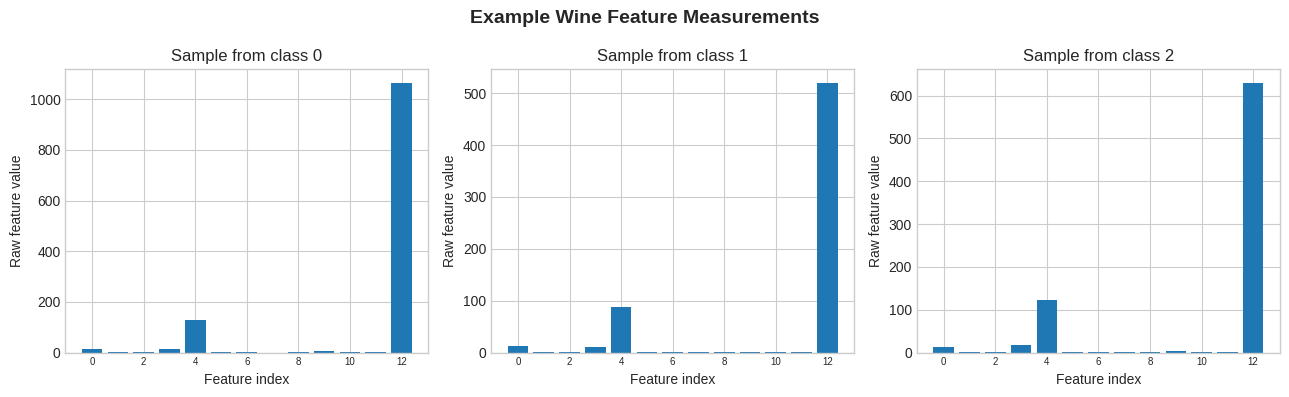

In [3]:
# Visualize sample feature values from each wine class

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for class_id, ax in enumerate(axes):
    sample = X[y == class_id][0]
    ax.bar(range(len(wine.feature_names)), sample)
    ax.set_title(f"Sample from class {class_id}")
    ax.set_xlabel("Feature index")
    ax.set_ylabel("Raw feature value")
    ax.tick_params(axis="x", labelsize=7)
plt.suptitle("Example Wine Feature Measurements", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


In [4]:
# Train / Validation / Test Split, then standardize features

X_train_full, X_test, y_train_full_int, y_test_int = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train_int, y_val_int = train_test_split(
    X_train_full, y_train_full_int, test_size=0.2,
    random_state=42, stratify=y_train_full_int
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype("float32")
X_val = scaler.transform(X_val).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

num_classes = len(np.unique(y))
y_train = tf.keras.utils.to_categorical(y_train_int, num_classes=num_classes)
y_val = tf.keras.utils.to_categorical(y_val_int, num_classes=num_classes)
y_test = tf.keras.utils.to_categorical(y_test_int, num_classes=num_classes)

print("Train shape     :", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape      :", X_test.shape)
print("Output classes  :", num_classes)
print("Standardized training feature mean (approx.):", round(float(X_train.mean()), 4))


Train shape     : (113, 13)
Validation shape: (29, 13)
Test shape      : (36, 13)
Output classes  : 3
Standardized training feature mean (approx.): -0.0


In [5]:
# Build the Feedforward Neural Network for 3-class classification

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(num_classes, activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,027 (4.01 KB)

 Trainable params: 1,027 (4.01 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train the Network with Early Stopping (Backpropagation)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True
    )],
)

print(f"Training finished after {len(history.history['loss'])} epochs.")


Training finished after 100 epochs.


In [7]:
# Evaluate on the Test Set

test_probabilities = model.predict(X_test, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=1)
test_true = y_test_int

test_accuracy = accuracy_score(test_true, test_predictions)
print(f"Test Accuracy: {test_accuracy:.4f}")
print(classification_report(
    test_true, test_predictions, labels=range(num_classes),
    target_names=class_names, zero_division=0
))


Test Accuracy: 0.9722
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



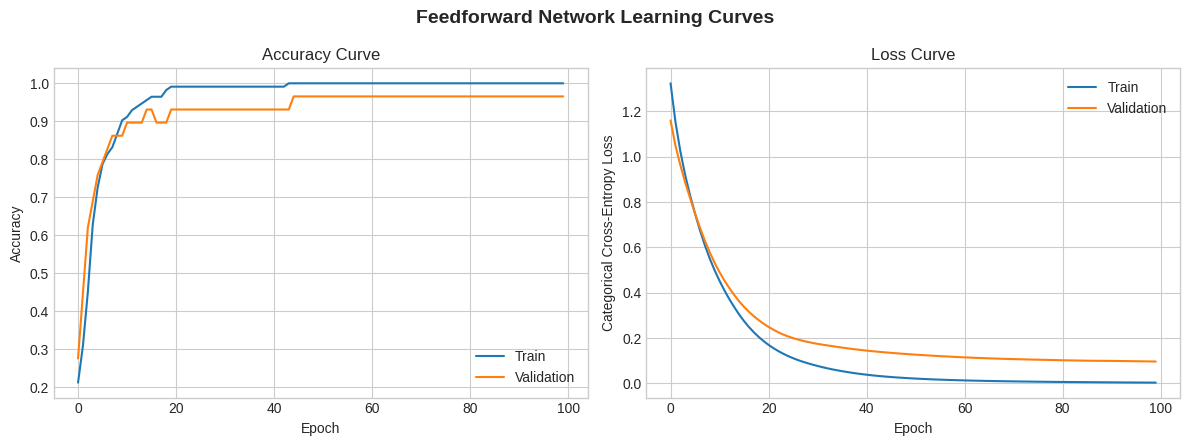

In [8]:
# Training vs Validation Accuracy and Loss Curves

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Categorical Cross-Entropy Loss")
axes[1].legend()

plt.suptitle("Feedforward Network Learning Curves", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


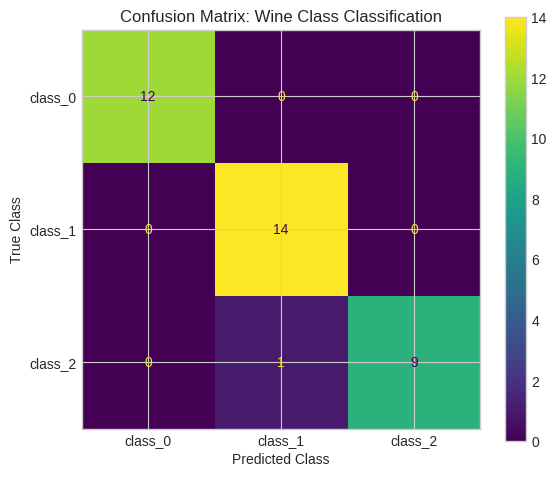

In [9]:
# Confusion Matrix

cm = confusion_matrix(test_true, test_predictions, labels=range(num_classes))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, colorbar=True, values_format="d")
plt.title("Confusion Matrix: Wine Class Classification")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()


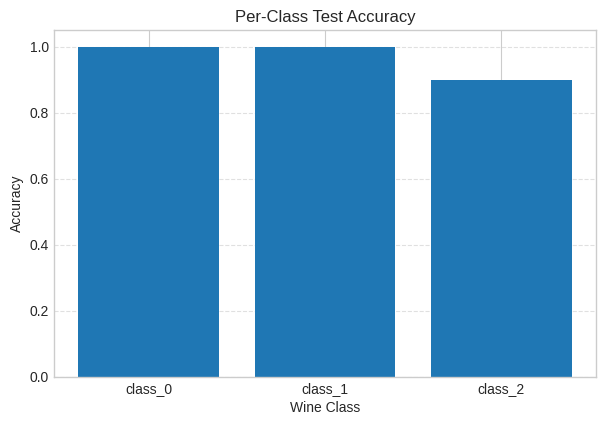

In [10]:
# Per-Class Accuracy

per_class_accuracy = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)

plt.figure(figsize=(7, 4.5))
plt.bar(class_names, per_class_accuracy)
plt.xlabel("Wine Class")
plt.ylabel("Accuracy")
plt.title("Per-Class Test Accuracy")
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()


In [11]:
# Inspect correctly and incorrectly classified test samples

misclassified = np.where(test_predictions != test_true)[0]
correct = np.where(test_predictions == test_true)[0]

print(f"Correctly classified: {len(correct)} / {len(test_true)}")
print(f"Misclassified      : {len(misclassified)} / {len(test_true)}")

print("\nSample correct predictions (true class -> predicted class):")
for idx in correct[:5]:
    print(f"Sample {idx}: {class_names[test_true[idx]]} -> {class_names[test_predictions[idx]]}")

print("\nSample misclassified predictions (true class -> predicted class):")
for idx in misclassified[:5]:
    print(f"Sample {idx}: {class_names[test_true[idx]]} -> {class_names[test_predictions[idx]]}")


Correctly classified: 35 / 36
Misclassified      : 1 / 36

Sample correct predictions (true class -> predicted class):
Sample 0: class_0 -> class_0
Sample 2: class_0 -> class_0
Sample 3: class_1 -> class_1
Sample 4: class_1 -> class_1
Sample 5: class_0 -> class_0

Sample misclassified predictions (true class -> predicted class):
Sample 1: class_2 -> class_1


## **Expected Output**

After running all cells, the notebook should display:

- Dataset shape, 13 feature names, and counts for the three wine classes.
- Example feature measurements for samples from each class.
- Training, validation, and test set shapes after standardization.
- The network summary and the epoch at which early stopping stopped training.
- Test accuracy and a classification report for all three classes.
- Accuracy and loss learning curves.
- A three-class confusion matrix and per-class accuracy chart.
- Examples of correctly classified and misclassified test samples.

Include the actual outputs generated by your run in the lab report.


## **Performance Evaluation**

The model is evaluated using training and validation curves, test accuracy, precision, recall, F1-score, the confusion matrix, and per-class accuracy. Standardization helps put the 13 numeric features on comparable scales. A small gap between training and validation performance may indicate good generalization, while a widening gap can indicate overfitting. The confusion matrix shows which wine classes are most often confused.


## **Discussion**

In this experiment, a feedforward neural network is trained on the Wine Recognition dataset to classify samples into three wine classes using 13 chemical-analysis features. Backpropagation computes gradients of the loss, and the Adam optimizer updates the network weights. Standardizing the features supports stable training because the measurements use different scales. The classification report and confusion matrix help evaluate performance across all classes. Since the dataset is relatively small, test results can vary with the train/test split and model settings, so the reported metrics should be taken from the notebook run rather than assumed in advance.


## **Viva Questions**

1. **Q:** What is a feedforward neural network?  
   **A:** A network where data flows from the input layer to the output layer through one or more hidden layers without cycles.

2. **Q:** What does backpropagation compute?  
   **A:** The gradients of the loss with respect to every weight in the network, using the chain rule.

3. **Q:** Why is the Adam optimizer popular?  
   **A:** It combines momentum with adaptive, per-parameter learning rates, which usually leads to fast and stable convergence.

4. **Q:** What is the purpose of an activation function such as ReLU?  
   **A:** To introduce non-linearity, allowing the network to model complex relationships instead of only linear ones.

5. **Q:** Why is one-hot encoding used for the labels here?  
   **A:** Because the output layer uses softmax with categorical cross-entropy, which compares a probability distribution against a one-hot target vector.

6. **Q:** What is early stopping, and why use it?  
   **A:** Stopping training when validation performance stops improving for a set number of epochs, to prevent overfitting and save training time.

7. **Q:** Why is the Wine Recognition dataset useful for this experiment?  
   **A:** It is small, requires no download, and is well suited to demonstrating multiclass feedforward training quickly.

8. **Q:** What is the role of the hidden layers?  
   **A:** To learn intermediate feature representations from the raw pixel input that make the classes easier to separate.

9. **Q:** What does a rising validation loss alongside falling training loss indicate?  
   **A:** Overfitting — the model is fitting the training data at the expense of generalization.

10. **Q:** Why is a confusion matrix useful beyond overall accuracy?  
    **A:** It shows exactly which classes are being confused with each other, which a single accuracy number cannot reveal.

## **Exercises**

Complete the following tasks after running the notebook:

1. Change the number of hidden units (e.g. 64/32 instead of 128/64) and compare the test accuracy.
2. Try `tanh` activation instead of `relu` in the hidden layers and observe the effect on convergence speed.
3. Add a `Dropout` layer after each hidden layer and check whether validation loss improves or the train/validation gap narrows.
4. Train the network without early stopping (set a high fixed number of epochs) and compare the resulting learning curves.
5. Replace the Wine Recognition dataset with another multiclass dataset from Scikit-learn (e.g. `load_breast_cancer`) and adapt the input/output layer sizes accordingly.

## **Lab Report Submission Checklist**

Before submitting, confirm that your report includes:

- Completed cover information.
- Objective and theory summary in your own words.
- All important code outputs, including the classification report.
- The learning curves, confusion matrix, per-class accuracy chart, and sample prediction outputs.
- Short discussion of which wine classes were most often confused and why.
- Answers to assigned viva questions.
- Completed exercises.

**Reminder:** A good lab report should not only show screenshots. It should explain what the outputs mean.
